# M14.2 — Evaluación del banco de filtros adaptados (4a-G3T, val G3T)

## 0. Procedencia y criterios (enmienda 2)

**Pre-registro:** `docs/experiments/M14_2_template_bank.md` (10-11-2026), enmiendas 1 y 2. La enmienda 2 se escribió antes de ver las predicciones de M14.2.

- **Modelo:** `M14_2_4a_G3T_tbank_s123` (último epoch, `_final.pt`). **Referencia:** `M13_13_4a_G3T_s123`, el mismo npz de val G3T que en M14.1. Son 40 000 filas emparejadas de val G3T.
- **Ruido de semilla en D8–D10 (sección 1, antes de cargar M14.2):** se usa el par 4a-aug G3 s123/s124 en val G3, con la definición de M13_6 §3b. Para cada decil d de τ30 y cada etiqueta, ruido_d = 100·|RMSE_s123 − RMSE_s124| / media del par. El ruido de D8–D10 es el máximo de ruido_d en D8, D9 y D10 (regla de la fila D8–D10 de §3b). Es una aproximación: no hay dos semillas de 4a en G3T. El umbral es 2 × ruido, por etiqueta.
- **Primario:** ΔRMSE% = 100·(RMSE_M14.2 / RMSE_ref − 1) de chirp_mass y χ_eff en el grupo D8–D10. El bootstrap es emparejado: B = 2000, `default_rng(142002)`, una extracción de filas por réplica compartida por las tres etiquetas. Hay mejora resuelta en una etiqueta si −ΔRMSE% > 2 × ruido de esa etiqueta.
- **Salvaguarda:** se evalúan las celdas no primarias de 3 etiquetas × {global, D1–D3, D4–D7, D8–D10}, es decir, 10 celdas. Cada celda PASA si IC sup ≤ +4 %, FALLA si el punto > +4 % e INDETERMINADO en otro caso.
- **Veredicto:** mejora resuelta si se cumple en al menos una etiqueta primaria y ninguna celda de la salvaguarda FALLA.
- **Orden del generador `default_rng(142002)`, fijo:** D8–D10 (primario y total_mass D8–D10), global, D1–D3, D4–D7 y, en los descriptivos, D1, …, D10.
- **Descriptivos:**
  - ΔRMSE por decil con IC;
  - RMSE de χ_eff en D10 de los dos modelos frente al suelo de 4a-G3T (0,207);
  - solape normalizado entre las plantillas iniciales y las finales (opcional, requiere torch).
- **Deciles de τ30:** τ30 newtoniano con la Mc verdadera y bordes en los cuantiles de val, con el mismo código que M14.1 y M13_6.

In [1]:
# 0. Parámetros, rutas y CONFIG (esta celda no carga datos)
import json
import sys
import warnings
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / 'AGENTS.md').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.paths import resolve_data_root
# Read-only reuse, as in M14.1: pinned G1 contract and tau30 of M13.1.
from scripts.m12.m12_5_3_posthoc_check import LABELS, digest, load_contract, npz_to_physical, require
from scripts.m13.m13_1_diagnostics import tau_newtonian

cfg = json.loads((ROOT / 'configs/experiments/train_m11_final_G1_500k.json').read_text())
DATA_ROOT = resolve_data_root(config_data_root=cfg.get('data_root'))
M13_DIR = DATA_ROOT / 'results' / 'M13_3'
VAL_NPZ = 'val_predictions_embeddings.npz'

# ---- Names and inputs (figures and tables take model and label names from here) --------------------------------
CONFIG = dict(
    models=dict(
        tbank=dict(tag='M14_2_4a_G3T_tbank_s123', name='M14.2 (4a-G3T tbank s123)'),
        ref=dict(tag='M13_13_4a_G3T_s123', name='4a-G3T s123 (ref.)'),
        seed_a=dict(tag='M13_4a_G3aug_s123', name='4a-aug G3 s123'),
        seed_b=dict(tag='M13_4a_G3aug_s124', name='4a-aug G3 s124'),
    ),
    labels={'chirp_mass': 'chirp mass', 'total_mass': 'total mass', 'chi_eff': 'χ_eff'},
    units={'chirp_mass': 'M☉', 'total_mass': 'M☉', 'chi_eff': 'adim.'},
    colors=dict(tbank='#2a6fb0', ref='0.35', noise='#c4512b', zero='0.3', i='#2a6fb0', q='#c4512b'),
    fig_names=dict(deciles='M14_2_drmse_by_tau30_decile', overlap='M14_2_template_overlap'),
)
TAG_T, TAG_R = CONFIG['models']['tbank']['tag'], CONFIG['models']['ref']['tag']
TAG_SA, TAG_SB = CONFIG['models']['seed_a']['tag'], CONFIG['models']['seed_b']['tag']
PRED_T, PRED_R = M13_DIR / TAG_T / VAL_NPZ, M13_DIR / TAG_R / VAL_NPZ   # PRED_R: same npz as M14.1
PRED_SA, PRED_SB = M13_DIR / TAG_SA / VAL_NPZ, M13_DIR / TAG_SB / VAL_NPZ   # M13_6 §3b pair (val G3)
HIST_T = M13_DIR / TAG_T / 'history.npz'          # trainer record: val_mse per epoch (standardized)
RUN_INFO_T = M13_DIR / TAG_T / 'run_info.json'    # procedure.template_bank
CKPT_T = DATA_ROOT / 'models' / 'checkpoints' / 'M13_3' / f'{TAG_T}_final.pt'
OUT_DIR = M13_DIR / TAG_T
FIG_DIR = OUT_DIR / 'figures'
G3T_MARK = 'm13_13_g3t'
# -----------------------------------------------------------------------------------------------------------------

# Gates.
N_EXPECTED = 40000
MSE_TOL = 5e-4                                     # standardized val MSE of M14.2 vs last epoch of history.npz
RMSE_REF = [(5.248, 3), (8.760, 3), (0.1677, 4)]   # physical RMSE of 4a-G3T s123 on val G3T (value, decimals)
# Seed noise of the 4a-aug pair for chi_eff, as printed by M13_6 §3b (provenance check of the reused definition).
M13_6_NOISE_4A_CHI = {'D8': 1.1913, 'D9': 3.5565, 'D10': 4.734}
M13_6_NOISE_TOL = 5e-4

# Pre-registered settings (doc M14.2, enmienda 2).
N_BOOT = 2000
BLOCK = 200                                        # replicates per vectorised block (memory only; does not change draws)
SEED = 142002
SEED_K = 2.0
SAFE_MAX_PCT = 4.0
PRIMARY_LABELS = ['chirp_mass', 'chi_eff']
LONG_DECILES = ['D8', 'D9', 'D10']
SAFE_GROUPS = ['global', 'D1-D3', 'D4-D7', 'D8-D10']
CHI_D10_FLOOR = 0.207                              # chi_eff RMSE floor of 4a-G3T in D10 (descriptive)
RUN_UTC = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
SUMMARY_PATH = OUT_DIR / f'M14_2_evaluation_summary_{RUN_UTC}.json'
print(DATA_ROOT)
print('Run stamp:', RUN_UTC)

/data/vserrano/cbc_pe_data
Run stamp: 20261111T224229Z


## 1. Ruido de semilla en D8–D10 (G3, par 4a-aug s123/s124, definición de M13_6 §3b)

**Esta celda no carga M14.2.** Los dos npz de val G3 tienen que cumplir el contrato G1 (mismas filas, mismo orden, mismas `y`). Se usan los deciles de τ30 con la Mc verdadera de val, con el mismo código de M13_6 §3, y para cada etiqueta y decil se calcula ruido_d = 100·|RMSE_s123 − RMSE_s124| / media. El ruido de D8–D10 es el máximo en D8, D9 y D10; el umbral es 2 × ese valor. El ruido del grupo D8–D10 agregado se da solo como descriptivo. Para χ_eff, los valores por decil se comprueban frente a los que imprimió M13_6 §3b.

In [2]:
# 1. Seed noise (G3 4a-aug pair); M14.2 is not loaded here
paths, splits, c_mean, c_std, identity = load_contract(DATA_ROOT)
checks = ['frozen G1 contract (g1_npe_contract.load_contract)']


def check(ok, name):
    require(bool(ok), 'Check failed: ' + name)
    checks.append(name)


def load_val(path, name, ckpt_expected, g3t):
    # Adapted from load_val of M14.1 (cell 2), without sigma. Only the keys below are read (allow_pickle=False).
    # g3t=True: memmap_dir must be under m13_13_g3t; g3t=False (G3 seed pair): it must not be (if recorded).
    require(path.exists(), f'{name}: missing {path}')
    with np.load(path, allow_pickle=False) as a:
        keys = set(a.files)
        f_s = a['pred_val'].astype(np.float64)
        y_raw = a['y_val']
        idx = a['idx_val'].astype(np.int64)
        y_mean, y_std = a['y_mean'].astype(np.float64), a['y_std'].astype(np.float64)
        label_names = a['label_names'].tolist()
        split_name = Path(str(a['split_path'])).name
        ckpt_name = Path(str(a['checkpoint_file'])).name if 'checkpoint_file' in keys else None
        memmap_dir = str(a['memmap_dir']) if 'memmap_dir' in keys else None
    y_s = y_raw.astype(np.float64)
    n = len(idx)
    check(f_s.shape == y_s.shape == (n, 3), f'{name}: shapes')
    check(label_names == LABELS, f'{name}: label order {LABELS}')
    check(split_name == paths['split_file'].name, f'{name}: split_path is the pinned split file')
    check(np.allclose(y_mean, c_mean, rtol=1e-6) and np.allclose(y_std, c_std, rtol=1e-6, atol=1e-8),
          f'{name}: npz y_mean/y_std equal M11 train-only label stats')
    check(np.all(np.diff(idx) > 0), f'{name}: idx_val strictly ascending (no duplicates)')
    check(np.isfinite(f_s).all() and np.isfinite(y_s).all(), f'{name}: finite pred/y')
    if ckpt_name is None:
        warnings.warn(f'{name}: npz has no checkpoint_file; checkpoint not verified')
    else:
        check(ckpt_name == ckpt_expected, f'{name}: checkpoint is {ckpt_expected}')
    if g3t:
        check(memmap_dir is not None and G3T_MARK in memmap_dir, f'{name}: memmap_dir is under {G3T_MARK}')
    elif memmap_dir is not None:
        check(G3T_MARK not in memmap_dir, f'{name}: memmap_dir is G3 (not {G3T_MARK})')
    y, f, units = npz_to_physical(y_s, f_s, c_mean, c_std)
    check(units == 'standardized', f'{name}: npz pred/y standardized (trainer contract)')
    check(np.all(np.abs(f.mean(0) - y.mean(0)) < 0.1 * c_std), f'{name}: pred in units of y')
    return dict(f=f, y=y, f_s=f_s, y_s=y_s, y_raw=y_raw, idx=idx, ckpt=ckpt_name, memmap_dir=memmap_dir)


def tau_deciles(Y):
    # tau30 deciles: code of M13_6 §3 / M14.1 cell 3, unchanged (Newtonian tau30 of the TRUE Mc, val quantile edges).
    tau30 = tau_newtonian(Y[:, 0])
    edges = np.quantile(tau30, np.linspace(0, 1, 11))
    return edges, np.clip(np.searchsorted(edges[1:-1], tau30, side='right'), 0, 9)


SA = load_val(PRED_SA, 'seed s123 (G3)', f'{TAG_SA}_final.pt', g3t=False)
SB = load_val(PRED_SB, 'seed s124 (G3)', f'{TAG_SB}_final.pt', g3t=False)
check(np.array_equal(SA['idx'], SB['idx']), 'seed pair: identical idx_val')
check(len(SA['idx']) == N_EXPECTED, f'seed pair: N = {N_EXPECTED}')
check(np.array_equal(SA['idx'], np.sort(splits['val'])), 'seed pair: idx_val equals val membership')
check(np.array_equal(SA['y_raw'], SB['y_raw']), 'seed pair: identical y_val (bitwise)')
Y_G3 = SA['y']
TAU_EDGES_G3, TDEC_G3 = tau_deciles(Y_G3)
DEC = [f'D{d + 1}' for d in range(10)]

noise_rows = []
for d, dn in enumerate(DEC):
    g = TDEC_G3 == d
    ra = np.sqrt(np.mean((SA['f'][g] - Y_G3[g])**2, 0))
    rb = np.sqrt(np.mean((SB['f'][g] - Y_G3[g])**2, 0))
    for j, lab in enumerate(LABELS):
        noise_rows.append(dict(decile=dn, label=lab, n=int(g.sum()), rmse_s123=ra[j], rmse_s124=rb[j],
                               noise_pct=100.0 * abs(ra[j] - rb[j]) / np.mean([ra[j], rb[j]])))
T_NOISE = pd.DataFrame(noise_rows)
for dn, v in M13_6_NOISE_4A_CHI.items():
    got = T_NOISE[(T_NOISE.decile == dn) & (T_NOISE.label == 'chi_eff')].noise_pct.iloc[0]
    check(abs(got - v) <= M13_6_NOISE_TOL, f'chi_eff seed noise {dn} = M13_6 §3b ({v})')

# D8-D10 seed noise (M13_6 §3b rule for the D8-D10 row: max over D8, D9, D10), per label; threshold 2x.
long = T_NOISE[T_NOISE.decile.isin(LONG_DECILES)]
SEED_NOISE_LONG = {lab: float(long[long.label == lab].noise_pct.max()) for lab in LABELS}
SEED_NOISE_ARGMAX = {lab: str(long[long.label == lab].set_index('decile').noise_pct.idxmax()) for lab in LABELS}
THRESH = {lab: SEED_K * SEED_NOISE_LONG[lab] for lab in LABELS}
# Descriptive only: noise of the pooled D8-D10 group.
gl = TDEC_G3 >= 7
ra = np.sqrt(np.mean((SA['f'][gl] - Y_G3[gl])**2, 0))
rb = np.sqrt(np.mean((SB['f'][gl] - Y_G3[gl])**2, 0))
SEED_NOISE_POOLED = {lab: float(100.0 * abs(ra[j] - rb[j]) / np.mean([ra[j], rb[j]])) for j, lab in enumerate(LABELS)}
T_THRESH = pd.DataFrame([dict(label=lab, noise_D8_D10_max_pct=SEED_NOISE_LONG[lab], from_decile=SEED_NOISE_ARGMAX[lab],
                              threshold_pct=THRESH[lab], noise_pooled_D8_D10_pct_descriptive=SEED_NOISE_POOLED[lab])
                         for lab in LABELS])
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_NOISE.pivot(index='decile', columns='label', values='noise_pct').reindex(DEC)[LABELS])
    display(T_THRESH)
print('Umbral primario (2 × ruido de semilla D8–D10):', {k: round(v, 3) for k, v in THRESH.items()})

label,chirp_mass,total_mass,chi_eff
decile,,,
D1,2.751,2.603,0.9046
D2,2.284,2.288,1.173
D3,0.3131,1.504,1.345
D4,0.4823,1.222,0.8397
D5,0.3756,0.8656,1.643
D6,2.375,3.882,1.047
D7,0.9819,0.7174,2.337
D8,3.548,1.607,1.191
D9,3.136,1.235,3.557


,label,noise_D8_D10_max_pct,from_decile,threshold_pct,noise_pooled_D8_D10_pct_descriptive
0,chirp_mass,3.548,D8,7.097,3.29
1,total_mass,1.607,D8,3.214,1.443
2,chi_eff,4.734,D10,9.468,3.527


Umbral primario (2 × ruido de semilla D8–D10): {'chirp_mass': 7.097, 'total_mass': 3.214, 'chi_eff': 9.468}


## 2. Carga y gates

- npz de val de M14.2 y de la referencia (el mismo npz que en M14.1), con `idx` e `y` idénticos, N = 40 000 e `idx` = pertenencia a val.
- Mismas filas y mismas `y` que el par de G3, de modo que los bordes de decil coinciden con los de la sección 1.
- MSE estandarizado de μ en M14.2 frente a la última época de `history.npz` del entrenador (`val_mse`), con tolerancia 5e-4. El valor se lee de ese fichero; no está escrito a mano.
- RMSE física de la referencia: 5,248 / 8,760 / 0,1677 (al redondeo).

In [3]:
# 2. Load and GATES (require aborts on the first failure)
for name, p in (('pred/tbank', PRED_T), ('pred/ref', PRED_R), ('history/tbank', HIST_T)):
    require(p.exists(), f'Missing {name}: {p}')
sha = {'pred/tbank': digest(PRED_T), 'pred/ref': digest(PRED_R), 'pred/seed_a': digest(PRED_SA),
       'pred/seed_b': digest(PRED_SB)}
T = load_val(PRED_T, 'tbank', f'{TAG_T}_final.pt', g3t=True)
R = load_val(PRED_R, 'ref', f'{TAG_R}_final.pt', g3t=True)
IDX = T['idx']
check(np.array_equal(R['idx'], IDX), 'G1: identical idx_val (same rows, same order)')
check(len(IDX) == N_EXPECTED, f'G1: N = {N_EXPECTED}')
check(np.array_equal(IDX, np.sort(splits['val'])), 'G1: idx_val equals val membership')
check(T['y_raw'].dtype == R['y_raw'].dtype and np.array_equal(T['y_raw'], R['y_raw']), 'G1: identical y_val (bitwise)')
check(not np.array_equal(T['f_s'], R['f_s']), 'G1: M14.2 and reference predictions differ')
check(np.array_equal(IDX, SA['idx']), 'G3T val rows = G3 val rows of the seed pair')
check(np.allclose(T['y'], Y_G3, rtol=1e-6, atol=1e-6), 'G3T y_val = G3 y_val (shared labels)')
gates = {'G1': dict(n=int(len(IDX)), idx_identical=True, y_identical=True)}

# MSE of M14.2 (standardized, mu) vs the last epoch recorded by the trainer.
with np.load(HIST_T, allow_pickle=False) as h:
    hist_epoch = h['epoch'].astype(int)
    hist_val_mse = np.asarray(h['val_mse'], dtype=np.float64)
    hist_val_loss = np.asarray(h['val_loss'], dtype=np.float64)
check(hist_val_mse.ndim == 2 and hist_val_mse.shape[1] == 3, 'history.npz: val_mse (epochs, 3)')
MSE_LOG, MSE_LOG_MEAN, LAST_EPOCH = hist_val_mse[-1], float(hist_val_loss[-1]), int(hist_epoch[-1])
mse_std = np.mean((T['f_s'] - T['y_s'])**2, 0)
print(f'MSE estandarizado de M14.2: {dict(zip(LABELS, mse_std.round(5)))} | media {mse_std.mean():.5f}')
print(f'history.npz, última época ({LAST_EPOCH}): {dict(zip(LABELS, MSE_LOG.round(5)))} | val_loss {MSE_LOG_MEAN:.5f}')
check(np.all(np.abs(mse_std - MSE_LOG) <= MSE_TOL), f'G2: per-label standardized MSE = last epoch of history.npz (tol {MSE_TOL:g})')
check(abs(mse_std.mean() - MSE_LOG_MEAN) <= MSE_TOL, f'G2: mean standardized MSE = last val_loss (tol {MSE_TOL:g})')
gates['G2'] = dict(mse_std=mse_std, mse_std_mean=float(mse_std.mean()), history_last_epoch=LAST_EPOCH,
                   history_val_mse=MSE_LOG, history_val_loss=MSE_LOG_MEAN, tol=MSE_TOL)

# Physical RMSE of the reference reproduces 5.248 / 8.760 / 0.1677 (to the rounding).
Y = T['y']
rmse_ref_g3 = np.sqrt(np.mean((R['f'] - Y)**2, 0))
print('RMSE física de la referencia:', dict(zip(LABELS, rmse_ref_g3.round(5))))
for j, (v, d) in enumerate(RMSE_REF):
    check(abs(round(float(rmse_ref_g3[j]), d) - v) < 1e-9, f'G3: RMSE_ref {LABELS[j]} rounds to {v}')
gates['G3'] = dict(rmse_ref=rmse_ref_g3, expected=[v for v, _ in RMSE_REF])

# Groups on val G3T (same rows and labels as the seed pair, so the same decile edges).
TAU_EDGES, TDEC = tau_deciles(Y)
check(np.array_equal(TAU_EDGES, TAU_EDGES_G3) and np.array_equal(TDEC, TDEC_G3), 'tau30 deciles = those of section 1')
N = len(Y)
GROUPS = {**{k: TDEC == d for d, k in enumerate(DEC)}, 'D1-D3': TDEC <= 2, 'D4-D7': (TDEC >= 3) & (TDEC <= 6),
          'D8-D10': TDEC >= 7, 'global': np.ones(N, bool)}
check(sum(int(GROUPS[k].sum()) for k in ('D1-D3', 'D4-D7', 'D8-D10')) == N, 'tau groups partition val')
print('GATES passed:', len(checks), 'checks | n_val:', N)

MSE estandarizado de M14.2: {'chirp_mass': np.float64(0.09784), 'total_mass': np.float64(0.06103), 'chi_eff': np.float64(0.1373)} | media 0.09872
history.npz, última época (79): {'chirp_mass': np.float64(0.09784), 'total_mass': np.float64(0.06103), 'chi_eff': np.float64(0.1373)} | val_loss 0.09872
RMSE física de la referencia: {'chirp_mass': np.float64(5.24798), 'total_mass': np.float64(8.75978), 'chi_eff': np.float64(0.16767)}
GATES passed: 63 checks | n_val: 40000


## 3. Primario (pre-registrado, enmienda 2)

ΔRMSE% en D8–D10 de chirp_mass y χ_eff, con el IC del 95 % por percentiles del bootstrap emparejado. Es la misma función que el criterio 1 de M14.1: `default_rng(142002)` y una extracción por réplica compartida por las tres etiquetas. Hay mejora resuelta en una etiqueta si −ΔRMSE% > 2 × ruido de semilla de esa etiqueta en D8–D10. La decisión usa el punto; el IC se reporta.

In [4]:
# 3. PRIMARY
E2_T, E2_R = (T['f'] - Y)**2, (R['f'] - Y)**2
rng = np.random.default_rng(SEED)   # consumed in fixed order: D8-D10, global, D1-D3, D4-D7, then D1..D10


def drmse_boot(rows, rng):
    # Same as drmse_boot of M14.1 (cell 3): paired row bootstrap, one draw per replicate shared by the three labels.
    et, er = E2_T[rows], E2_R[rows]
    n = len(et)
    rt, rr = np.sqrt(et.mean(0)), np.sqrt(er.mean(0))
    reps = np.empty((N_BOOT, 3))
    for s in range(0, N_BOOT, BLOCK):
        m = min(BLOCK, N_BOOT - s)
        ii = rng.integers(0, n, size=(m, n))
        reps[s:s + m] = 100.0 * (np.sqrt(et[ii].mean(1)) / np.sqrt(er[ii].mean(1)) - 1.0)
    return rt, rr, 100.0 * (rt / rr - 1.0), reps


def drmse_table(group, rows, rng):
    rt, rr, pt, reps = drmse_boot(rows, rng)
    lo, hi = np.percentile(reps, [2.5, 97.5], axis=0)
    return [dict(group=group, label=lab, n=int(rows.sum()), rmse_ref=rr[j], rmse_tbank=rt[j], drmse_pct=pt[j],
                 ci95_lo=lo[j], ci95_hi=hi[j]) for j, lab in enumerate(LABELS)]


T_D810 = pd.DataFrame(drmse_table('D8-D10', GROUPS['D8-D10'], rng))
T_PRIM = T_D810[T_D810.label.isin(PRIMARY_LABELS)].copy()
T_PRIM['seed_noise_pct'] = T_PRIM.label.map(SEED_NOISE_LONG)
T_PRIM['threshold_pct'] = T_PRIM.label.map(THRESH)
T_PRIM['improved_resolved'] = -T_PRIM.drmse_pct > T_PRIM.threshold_pct
PRIMARY_RESOLVED = bool(T_PRIM.improved_resolved.any())
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_PRIM)
print('PRIMARIO (D8–D10):')
for r in T_PRIM.itertuples():
    print(f'  {r.label:10s} ΔRMSE {r.drmse_pct:+.2f} % [{r.ci95_lo:+.2f}; {r.ci95_hi:+.2f}] | umbral −{r.threshold_pct:.2f} % '
          f'→ {"MEJORA RESUELTA" if r.improved_resolved else "no resuelta"}')

,group,label,n,rmse_ref,rmse_tbank,drmse_pct,ci95_lo,ci95_hi,seed_noise_pct,threshold_pct,improved_resolved
0,D8-D10,chirp_mass,12000,3.937,3.81,-3.211,-4.705,-1.718,3.548,7.097,False
2,D8-D10,chi_eff,12000,0.1746,0.1659,-4.988,-6.265,-3.747,4.734,9.468,False


PRIMARIO (D8–D10):
  chirp_mass ΔRMSE -3.21 % [-4.71; -1.72] | umbral −7.10 % → no resuelta
  chi_eff    ΔRMSE -4.99 % [-6.26; -3.75] | umbral −9.47 % → no resuelta


## 4. Salvaguarda (pre-registrada, enmienda 2)

Son las 10 celdas no primarias de 3 etiquetas × {global, D1–D3, D4–D7, D8–D10}; total_mass D8–D10 sale de la misma extracción que el primario. Cada celda PASA si IC sup ≤ +4 %, FALLA si el punto > +4 % e INDETERMINADO en otro caso. El generador continúa en el orden global, D1–D3, D4–D7.

In [5]:
# 4. SAFEGUARD
def safe_verdict(pt, hi):
    if hi <= SAFE_MAX_PCT:
        return 'PASA'
    if pt > SAFE_MAX_PCT:
        return 'FALLA'
    return 'INDETERMINADO'


T_REST = pd.DataFrame([r for k in ('global', 'D1-D3', 'D4-D7') for r in drmse_table(k, GROUPS[k], rng)])
T_SAFE = pd.concat([T_REST, T_D810[~T_D810.label.isin(PRIMARY_LABELS)]], ignore_index=True)
check(len(T_SAFE) == 3 * len(SAFE_GROUPS) - len(PRIMARY_LABELS), 'safeguard: 10 non-primary cells')
T_SAFE['verdict'] = [safe_verdict(p, h) for p, h in zip(T_SAFE.drmse_pct, T_SAFE.ci95_hi)]
SAFE_ANY_FAIL = bool((T_SAFE.verdict == 'FALLA').any())
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_SAFE)
print('SALVAGUARDA:', T_SAFE.verdict.value_counts().to_dict(), '| alguna FALLA:', SAFE_ANY_FAIL)

,group,label,n,rmse_ref,rmse_tbank,drmse_pct,ci95_lo,ci95_hi,verdict
0,global,chirp_mass,40000,5.248,5.164,-1.608,-2.131,-1.085,PASA
1,global,total_mass,40000,8.76,8.573,-2.131,-2.678,-1.547,PASA
2,global,chi_eff,40000,0.1677,0.1632,-2.692,-3.178,-2.178,PASA
3,D1-D3,chirp_mass,12000,6.121,6.014,-1.757,-2.606,-0.9053,PASA
4,D1-D3,total_mass,12000,10.31,10.1,-2.085,-2.915,-1.285,PASA
5,D1-D3,chi_eff,12000,0.1808,0.178,-1.583,-2.237,-0.9072,PASA
6,D4-D7,chirp_mass,16000,5.397,5.352,-0.8321,-1.545,-0.109,PASA
7,D4-D7,total_mass,16000,8.482,8.315,-1.968,-2.897,-0.9686,PASA
8,D4-D7,chi_eff,16000,0.1513,0.1489,-1.627,-2.327,-0.9513,PASA
9,D8-D10,total_mass,12000,7.318,7.134,-2.516,-3.848,-1.176,PASA


SALVAGUARDA: {'PASA': 10} | alguna FALLA: False


## 5. Veredicto global (enmienda 2)

In [6]:
# 5. GLOBAL VERDICT
VERDICT = 'MEJORA RESUELTA' if (PRIMARY_RESOLVED and not SAFE_ANY_FAIL) else 'SIN MEJORA RESUELTA'
print('Primario: mejora resuelta en', [r.label for r in T_PRIM.itertuples() if r.improved_resolved] or 'ninguna etiqueta')
print('Salvaguarda: celdas que FALLAN:', T_SAFE[T_SAFE.verdict == 'FALLA'][['group', 'label']].to_dict('records') or 'ninguna')
print('VEREDICTO (pre-registrado):', VERDICT)

Primario: mejora resuelta en ninguna etiqueta
Salvaguarda: celdas que FALLAN: ninguna
VEREDICTO (pre-registrado): SIN MEJORA RESUELTA


## 6. Descriptivos (enmienda 2; no deciden)

ΔRMSE% por decil D1–D10 y etiqueta, con IC; el mismo generador continúa en el orden D1..D10. También la RMSE de χ_eff en D10 de los dos modelos frente al suelo de 4a-G3T (0,207).

In [7]:
# 6. DESCRIPTIVE: ΔRMSE% by decile (same rng, continuing D1..D10) and chi_eff RMSE in D10
T_DEC = pd.DataFrame([r for k in DEC for r in drmse_table(k, GROUPS[k], rng)])
T_DEC['seed_threshold_pct'] = T_DEC.label.map(THRESH)
with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200):
    display(T_DEC.pivot(index='group', columns='label', values='drmse_pct').reindex(DEC)[LABELS])
jc = LABELS.index('chi_eff')
d10 = T_DEC[(T_DEC.group == 'D10') & (T_DEC.label == 'chi_eff')].iloc[0]
CHI_D10 = dict(rmse_ref=float(d10.rmse_ref), rmse_tbank=float(d10.rmse_tbank), floor_4a_G3T=CHI_D10_FLOOR,
               drmse_pct=float(d10.drmse_pct), ci95_lo=float(d10.ci95_lo), ci95_hi=float(d10.ci95_hi))
print(f"χ_eff D10: RMSE ref {CHI_D10['rmse_ref']:.4f} | M14.2 {CHI_D10['rmse_tbank']:.4f} | suelo 4a-G3T {CHI_D10_FLOOR}")

label,chirp_mass,total_mass,chi_eff
group,,,
D1,-2.033,-1.466,-1.129
D2,-1.964,-2.746,-1.214
D3,-1.192,-2.296,-2.647
D4,-0.2552,-0.2474,-0.9991
D5,-0.7289,-2.464,-1.386
D6,0.06027,-1.848,-0.3882
D7,-2.385,-3.485,-3.649
D8,-2.47,-3.549,-5.085
D9,-2.491,-1.912,-5.619


χ_eff D10: RMSE ref 0.2074 | M14.2 0.1979 | suelo 4a-G3T 0.207


### 6b. Descriptivo opcional: solape entre plantillas iniciales y finales

Requiere torch en local. Del checkpoint `M13_3/M14_2_4a_G3T_tbank_s123_final.pt`, cargado en CPU, solo se usa el `state_dict` y no se construye el modelo. Las plantillas iniciales se reconstruyen como en `init_template_bank` (`scripts/m13/train_m13_3.py`), con las filas, detector y merger que registra `run_info.json → procedure.template_bank`. De `X_clean_train` se leen solo las 32 filas, por índice sobre el memmap. Se comprueba que el detector, la energía y el merger coinciden con lo registrado; una discrepancia se informa, no detiene la celda.

`set_templates` guarda los parámetros tal cual, con el merger al final. El forward normaliza cada plantilla y luego aplica el desplazamiento, así que el solape normalizado es ⟨t_ini, t_fin⟩ / (‖t_ini‖·‖t_fin‖) por plantilla k, en `template_i` y en `template_q`. Si falta algo, la celda informa y sigue.

In [8]:
# 6b. OPTIONAL: normalized overlap <t_ini, t_fin> per template (template_i and template_q)
OVERLAP, OVERLAP_NOTE, RECON_ISSUES = None, None, []
try:
    import torch
    from scripts.m13.train_m13_3 import AUG_ZSCORE_EPS, hilbert_quadrature   # same helpers as init_template_bank
except Exception as e:
    OVERLAP_NOTE = f'omitido: torch o scripts.m13.train_m13_3 no importables ({e!r})'
else:
    try:
        tb = json.loads(RUN_INFO_T.read_text())['procedure']['template_bank']
        L = int(tb['architecture']['template_length'])
        K = len(tb['templates'])
        try:
            ck = torch.load(CKPT_T, map_location='cpu', weights_only=False)   # trusted local checkpoint
        except TypeError:                                                   # older torch: no weights_only
            ck = torch.load(CKPT_T, map_location='cpu')
        sd = ck['model_state_dict']
        del ck
        fin = {}
        for part in ('template_i', 'template_q'):
            keys = [k for k in sd if k.endswith(f'template_bank.{part}')]
            require(len(keys) == 1, f'state_dict: expected one *template_bank.{part}, found {keys}')
            fin[part] = sd[keys[0]].detach().double().numpy()
            require(fin[part].shape == (K, L), f'{part}: shape {fin[part].shape} != {(K, L)}')
        del sd
        Xc = np.load(Path(tb['memmap_dir']) / 'X_clean_train.npy', mmap_mode='r')
        ini_i, ini_q = np.zeros((K, L)), np.zeros((K, L))
        for t in tb['templates']:
            k = int(t['k'])
            row = np.asarray(Xc[int(t['train_position'])], dtype=np.float64)   # one row of the memmap
            e = (row * row).sum(axis=1)
            d = int(np.argmax(e))
            if d != int(t['detector_index']) or not np.allclose(e, t['clean_energy'], rtol=1e-12, atol=0):
                RECON_ISSUES.append(dict(k=k, issue='detector/energy', recorded=t['detector_index'], got=d))
            s = row[int(t['detector_index'])]
            z = (s - s.mean()) / (s.std() + AUG_ZSCORE_EPS)
            p = int(np.argmax(np.abs(z + 1j * hilbert_quadrature(z))))
            if p != int(t['merger_index']):
                RECON_ISSUES.append(dict(k=k, issue='merger_index', recorded=t['merger_index'], got=p))
            p = int(t['merger_index'])
            seg = z[max(0, p - L + 1):p + 1]
            ini_i[k, L - seg.size:] = seg
            ini_q[k] = hilbert_quadrature(ini_i[k])
        del Xc

        def unit(a):
            return a / np.linalg.norm(a, axis=1, keepdims=True)

        ov = {part: np.sum(unit(a) * unit(fin[part]), axis=1) for part, a in (('template_i', ini_i), ('template_q', ini_q))}
        OVERLAP = pd.DataFrame([dict(k=int(t['k']), cell_tau_chi=t['cell_tau_chi'], tau30_s=t['tau30_s'],
                                     chi_eff=t['chi_eff'], overlap_i=float(ov['template_i'][int(t['k'])]),
                                     overlap_q=float(ov['template_q'][int(t['k'])])) for t in tb['templates']])
        OVERLAP_NOTE = (f'K = {K}, L = {L}; discrepancias de reconstrucción: {len(RECON_ISSUES)}')
    except Exception as e:
        OVERLAP_NOTE = f'omitido: {e!r}'
print('Solape:', OVERLAP_NOTE)
if RECON_ISSUES:
    display(pd.DataFrame(RECON_ISSUES))
if OVERLAP is not None:
    with pd.option_context('display.float_format', '{:.4g}'.format, 'display.width', 200, 'display.max_rows', 40):
        display(OVERLAP)
        display(OVERLAP[['overlap_i', 'overlap_q']].describe())

Solape: K = 32, L = 16384; discrepancias de reconstrucción: 0


,k,cell_tau_chi,tau30_s,chi_eff,overlap_i,overlap_q
0,0,"[0, 0]",0.07421,-0.7582,0.3876,0.3957
1,1,"[0, 1]",0.0664,-0.008685,0.378,0.3745
2,2,"[0, 2]",0.05904,0.1456,0.3511,0.3806
3,3,"[0, 3]",0.07536,0.455,0.4124,0.4104
4,4,"[1, 0]",0.08746,-0.5407,0.3812,0.3907
5,5,"[1, 1]",0.1087,-0.05459,0.5148,0.5208
6,6,"[1, 2]",0.1096,0.2005,0.3098,0.2953
7,7,"[1, 3]",0.09161,0.3679,0.45,0.4792
8,8,"[2, 0]",0.129,-0.4745,0.3412,0.3447
9,9,"[2, 1]",0.1122,-0.2309,0.3901,0.4205


,overlap_i,overlap_q
count,32,32
mean,0.3816,0.3944
std,0.0962,0.09604
min,0.1478,0.1107
25%,0.3401,0.3593
50%,0.3844,0.3943
75%,0.4234,0.4715
max,0.5992,0.5967


## 7. Figuras (PNG y PDF en `FIG_DIR`, con la marca UTC de la ejecución; no sobrescribe)

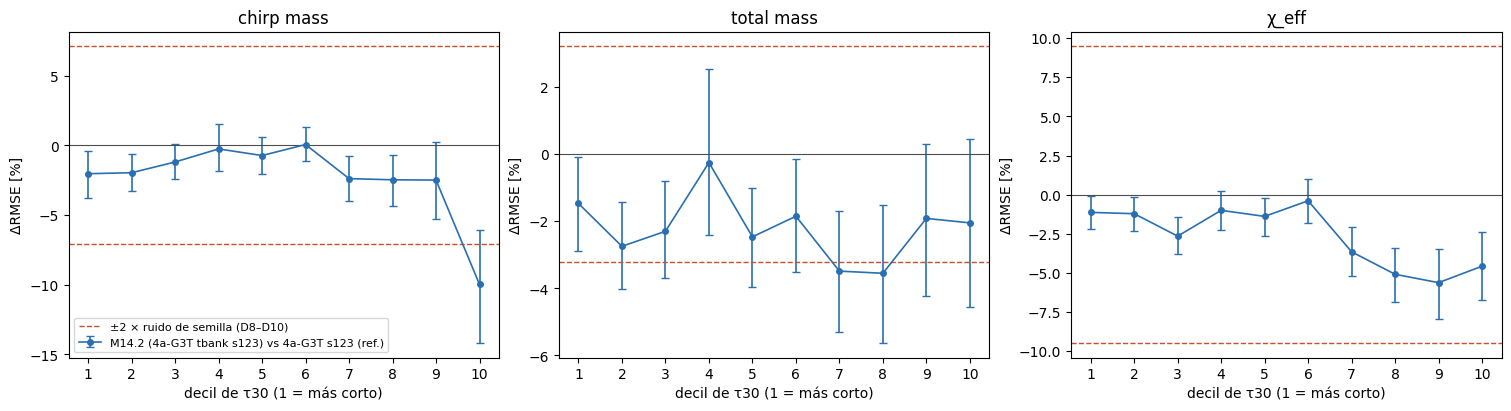

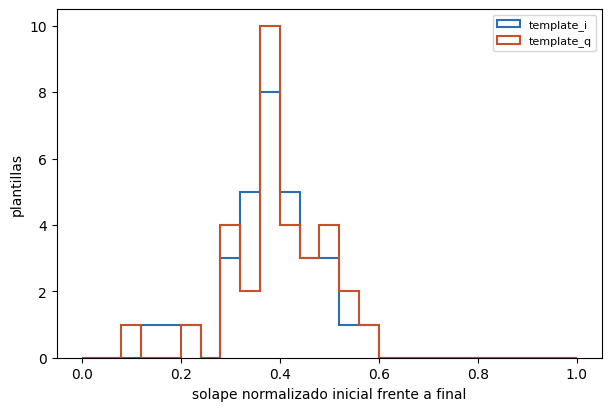

/data/vserrano/cbc_pe_data/results/M13_3/M14_2_4a_G3T_tbank_s123/figures/M14_2_drmse_by_tau30_decile_20261111T224229Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_2_4a_G3T_tbank_s123/figures/M14_2_drmse_by_tau30_decile_20261111T224229Z.pdf
/data/vserrano/cbc_pe_data/results/M13_3/M14_2_4a_G3T_tbank_s123/figures/M14_2_template_overlap_20261111T224229Z.png
/data/vserrano/cbc_pe_data/results/M13_3/M14_2_4a_G3T_tbank_s123/figures/M14_2_template_overlap_20261111T224229Z.pdf


In [9]:
# 7. Figures
LNAME, UNITS, COL, MNAME = CONFIG['labels'], CONFIG['units'], CONFIG['colors'], CONFIG['models']
FIG_DIR.mkdir(parents=True, exist_ok=True)
FIGURES = []


def save_figure(fig, key):
    for ext in ('png', 'pdf'):
        p = FIG_DIR / f"{CONFIG['fig_names'][key]}_{RUN_UTC}.{ext}"
        with p.open('xb') as fh:
            fig.savefig(fh, format=ext, dpi=200, bbox_inches='tight')
        FIGURES.append(str(p))


# ΔRMSE% by tau30 decile with 95 % CI and lines at ±2 x seed noise (D8-D10) of each label.
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
x = np.arange(1, 11)
for ax, lab in zip(axes, LABELS):
    t = T_DEC[T_DEC.label == lab].set_index('group').reindex(DEC)
    ax.errorbar(x, t.drmse_pct, yerr=[t.drmse_pct - t.ci95_lo, t.ci95_hi - t.drmse_pct], fmt='o-', ms=4, lw=1.2,
                capsize=3, color=COL['tbank'], label=f"{MNAME['tbank']['name']} vs {MNAME['ref']['name']}")
    ax.axhline(0, color=COL['zero'], lw=0.8)
    for sgn in (-1, 1):
        ax.axhline(sgn * THRESH[lab], color=COL['noise'], ls='--', lw=1,
                   label='±2 × ruido de semilla (D8–D10)' if sgn < 0 else None)
    ax.set(title=LNAME[lab], xlabel='decil de τ30 (1 = más corto)', ylabel='ΔRMSE [%]', xticks=x)
axes[0].legend(fontsize=8)
save_figure(fig, 'deciles')
plt.show()

if OVERLAP is not None:
    fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
    bins = np.linspace(min(OVERLAP.overlap_i.min(), OVERLAP.overlap_q.min(), 0.0), 1.0, 26)
    ax.hist(OVERLAP.overlap_i, bins=bins, histtype='step', lw=1.5, color=COL['i'], label='template_i')
    ax.hist(OVERLAP.overlap_q, bins=bins, histtype='step', lw=1.5, color=COL['q'], label='template_q')
    ax.set(xlabel='solape normalizado inicial frente a final', ylabel='plantillas')
    ax.legend(fontsize=8)
    save_figure(fig, 'overlap')
    plt.show()
else:
    print('Histograma de solapes omitido:', OVERLAP_NOTE)
print('\n'.join(FIGURES))

## 8. Resumen JSON (modo `'x'`: nunca sobrescribe)

In [10]:
# 8. Summary JSON
def to_json(o):
    if isinstance(o, dict):
        return {str(k): to_json(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_json(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_json(o.tolist())
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if not np.isfinite(o) else float(o)
    return o


summary = dict(
    experiment='M14.2', preregistration='docs/experiments/M14_2_template_bank.md (10-11-2026; enmiendas 1 y 2)',
    run_utc=RUN_UTC, models=CONFIG['models'],
    inputs=dict(pred_tbank=str(PRED_T), pred_ref=str(PRED_R), pred_seed_a=str(PRED_SA), pred_seed_b=str(PRED_SB),
                history_tbank=str(HIST_T), run_info_tbank=str(RUN_INFO_T), checkpoint_tbank=str(CKPT_T), sha256=sha),
    gates=gates, checks=checks,
    seed_noise=dict(definition='M13_6 §3b: 100*|RMSE_s123 - RMSE_s124| / pair mean per tau30 decile; D8-D10 = max '
                               'over D8, D9, D10; pair 4a-aug G3 s123/s124 on val G3 (approximation for G3T)',
                    k=SEED_K, per_decile=T_NOISE.to_dict('records'), d8_d10_max_pct=SEED_NOISE_LONG,
                    d8_d10_argmax=SEED_NOISE_ARGMAX, threshold_pct=THRESH,
                    pooled_d8_d10_pct_descriptive=SEED_NOISE_POOLED, m13_6_check_chi_eff=M13_6_NOISE_4A_CHI),
    bootstrap=dict(n_boot=N_BOOT, block=BLOCK, seed=SEED,
                   order='D8-D10, global, D1-D3, D4-D7, then D1..D10; one row draw per replicate shared by labels'),
    tau_edges_s=TAU_EDGES,
    primary=dict(table=T_PRIM.to_dict('records'), resolved=PRIMARY_RESOLVED),
    safeguard=dict(max_pct=SAFE_MAX_PCT, table=T_SAFE.to_dict('records'), any_fail=SAFE_ANY_FAIL),
    verdict=VERDICT,
    descriptive=dict(drmse_by_decile=T_DEC.to_dict('records'), chi_eff_d10=CHI_D10,
                     template_overlap=None if OVERLAP is None else OVERLAP.to_dict('records'),
                     template_overlap_note=OVERLAP_NOTE, template_reconstruction_issues=RECON_ISSUES),
    figures=FIGURES,
)
with SUMMARY_PATH.open('x', encoding='utf-8') as fh:
    json.dump(to_json(summary), fh, indent=2, ensure_ascii=False)
print('Summary:', SUMMARY_PATH)
print('VEREDICTO:', VERDICT)

Summary: /data/vserrano/cbc_pe_data/results/M13_3/M14_2_4a_G3T_tbank_s123/M14_2_evaluation_summary_20261111T224229Z.json
VEREDICTO: SIN MEJORA RESUELTA


## Lectura (11-11-2026)

**Veredicto pre-registrado (enmienda 2): SIN MEJORA RESUELTA.** No se adopta el banco; M14.5b (banco + covarianza completa) no se lanza.

### Verificado (val G3T, 40 000 filas; una semilla por modelo)
- **Gates:** 63 comprobaciones; MSE de M14.2 = última época del entrenador (0,09784 / 0,06103 / 0,1373); referencia 5,248 / 8,760 / 0,1677.
- **Ruido de semilla en D8–D10** (par 4a-aug G3 s123/s124, definición de M13_6 §3b, máximo de D8–D10): chirp 3,55 %, χ_eff 4,73 % → umbrales 7,10 % y 9,47 %. Los valores de χ_eff reproducen M13_6.
- **Primario (D8–D10):** chirp −3,21 % [−4,71; −1,72]; χ_eff −4,99 % [−6,26; −3,75]. Ninguno supera el umbral.
- **Salvaguarda:** 10/10 PASA. Global −1,61 / −2,13 / −2,69 %.
- **Descriptivo:**
  - ΔRMSE negativo en las 13 celdas, mayor en señales largas: χ_eff −3,6 a −5,6 % en D7–D10 frente a −0,4 a −2,6 % en D1–D6; chirp −10,0 % en D10.
  - RMSE de χ_eff en D10: 0,2074 → 0,1979.
  - Plantillas: solape normalizado inicial frente a final con mediana 0,38 (rango 0,11–0,60); reconstrucción de las iniciales sin discrepancias.

### Interpretación
- **(Pre-registrado):** la mejora en señales largas es del orden del ruido de semilla; con una semilla no se distingue de la variación entre entrenamientos. El IC por filas no incluye esa variación.
- **(Hipótesis):** el patrón (mejora en todas las celdas, creciente con la duración y con plantillas rediseñadas por la red) es coherente con una ganancia real y pequeña del banco en la dirección de la hipótesis B (acumulación de fase). Confirmarlo requiere varias semillas.
- **Coste:** ~2,5× de tiempo de entrenamiento y +1,07 M parámetros. Por la regla de adopción (a igual rendimiento, menor coste) no se adopta.

### No se puede concluir
- Que el banco no aporte nada (resultado nulo débil: K = 32, una semilla).
- El diseño óptimo del banco.
- El efecto en datos reales.